In [1]:
import pypsa
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
reference = pd.read_csv('/Users/ng-work/Models/pypsa-monte_carlo/results/example-50-discrete/welfare_by_country.csv')
cf_0_BE = pd.read_csv('/Users/ng-work/Models/pypsa-monte_carlo/results/example-50-BE/welfare_by_country.csv')
cf_0_NL = pd.read_csv('/Users/ng-work/Models/pypsa-monte_carlo/results/example-50-NL/welfare_by_country.csv')
cf_0_pool = pd.read_csv('/Users/ng-work/Models/pypsa-monte_carlo/results/example-50-pool/welfare_by_country.csv')

# cf_r_BE = pd.read_csv('/Users/ng-work/Models/pypsa-fbmc/tornado-analysis/results/obz_test_n_cf_r_BE/welfare_by_country.csv')
# cf_r_NL = pd.read_csv('/Users/ng-work/Models/pypsa-fbmc/tornado-analysis/results/obz_test_n_cf_r_NL/welfare_by_country.csv')
# cf_r_pool = pd.read_csv('/Users/ng-work/Models/pypsa-fbmc/tornado-analysis/results/obz_test_n_cf_r_pool/welfare_by_country.csv')
# cf_r_i_BE = pd.read_csv('/Users/ng-work/Models/pypsa-fbmc/tornado-analysis/results/obz_test_n_cf_r_i_BE/welfare_by_country.csv')
# cf_r_i_NL = pd.read_csv('/Users/ng-work/Models/pypsa-fbmc/tornado-analysis/results/obz_test_n_cf_r_i_NL/welfare_by_country.csv')
# cf_r_i_pool = pd.read_csv('/Users/ng-work/Models/pypsa-fbmc/tornado-analysis/results/obz_test_n_cf_r_i_pool/welfare_by_country.csv')


In [25]:
# welfare_by_country extracts the description of the scenario from the file parameter and direction. then, gives as output the aggregated welfare by country
def welfare_by_country(network_welfare, scenario):
#    network_welfare['description'] = network_welfare.sample
    network = network_welfare.query('sample == @scenario')
    return network.groupby("country").sum().total


#### NOTE: the function should be improved by putting value zero for the OBZs in the scenarios where they are not there // alternative chioce is to put 'country' == '{home_country}' in the network builder

In [43]:
welfare_by_country(cf_0_pool, 0)
#welfare_by_country(cf_r_pool, 'baseline - baseline')
#welfare_by_country(cf_r_i_pool, 'baseline - baseline')

country
BE    3.349997e+07
GB    1.199920e+07
LU    5.327628e+06
NL    3.409808e+07
Name: total, dtype: float64

In [96]:
cba(reference, cf_0_BE, 0)

country
BE        277640.170412
GB             0.000000
LU        272090.778081
NL       -317140.304848
OBZ_BE     29900.000000
OBZ_NL   -146272.664097
Name: total, dtype: float64

In [95]:
# cba() gives the Socio-Economic Welfare of a project (defined by the difference between the reference and the counterfactual configuration) for the selected scenario
def cba(reference, counterfactual, scenario):
    welfare_reference = welfare_by_country(reference, scenario)
    welfare_counterfactual = welfare_by_country(counterfactual, scenario)
    SEW = welfare_reference - welfare_counterfactual
    SEW = welfare_reference.sub(welfare_counterfactual, fill_value=0)
    return SEW

In [16]:
#this one can still be used if referred to the expected value
def assessment (df_effect):
    df_result = df_effect.copy()
    df_result["assessment"] = df_result.Pool.abs() - df_result.Sum.abs()
    return df_result.T

## interconnectivity

In [161]:
def interconnectivity(n):
    ic_capacity = pd.Series()
    gen_capacity = n.generators.groupby('bus').sum().p_nom
    for bus in n.buses.index.to_list():
        ic_capacity[bus]  = n.links.query('bus0 == @bus or bus1 == @bus').p_nom.sum()
    interconnectivity = ic_capacity.div(gen_capacity)
    return interconnectivity

In [162]:
interconnectivity(n)

BE        0.422535
GB        0.600000
LU        0.200000
NL        0.186047
OBZ_BE    2.000000
OBZ_NL    2.000000
dtype: float64

In [163]:
interconnectivity(n_li)

BE        0.239437
GB        0.600000
LU        0.080000
NL        0.125581
OBZ_BE    2.000000
OBZ_NL    2.000000
dtype: float64

In [587]:
n_tr = pypsa.Network("/Users/ng-work/Models/pypsa-fbmc/tornado-analysis/results/obz_test/cases/Less-transmission__down/network.nc")

INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, links, loads, sub_networks


In [590]:
interconnectivity(n_tr)

BE        0.281690
GB        0.600000
LU        0.200000
NL        0.139535
OBZ_BE    2.000000
OBZ_NL    2.000000
dtype: float64

## violin chart

In [229]:
counterfactuals = {
    "cf_0_BE": cf_0_BE,
    "cf_0_NL": cf_0_NL,
    "Bundle": cf_0_pool,
}

scenarios = reference["sample"].unique()
#["Demand level - BE - down", "Demand level - BE - up", "Demand level - NL - down",]

rows = []

for cf_name, cf in counterfactuals.items():
    for scenario in scenarios:
        #pe = perturbation_effect(reference, cf, scenario)
        pe = cba(reference, cf, scenario)
        for country, effect in pe.items():
            rows.append({
                "counterfactual": cf_name,
                "scenario": scenario,
    #            "max": pe.max(),
    #            "mean": pe.mean(),
                "country": country,
                "effect": effect,
            })

df = pd.DataFrame(rows)

cf_0_sum = (
    df[df["counterfactual"].isin(["cf_0_BE", "cf_0_NL"])]
    .groupby(["scenario", "country"], as_index=False)["effect"]
    .sum()
)

cf_0_sum["counterfactual"] = "Sum of projects"

df = pd.concat([df, cf_0_sum], ignore_index=True)

In [230]:
df['effect_centered'] = df['effect'] - df.groupby(["country", "counterfactual"])["effect"].transform("mean")

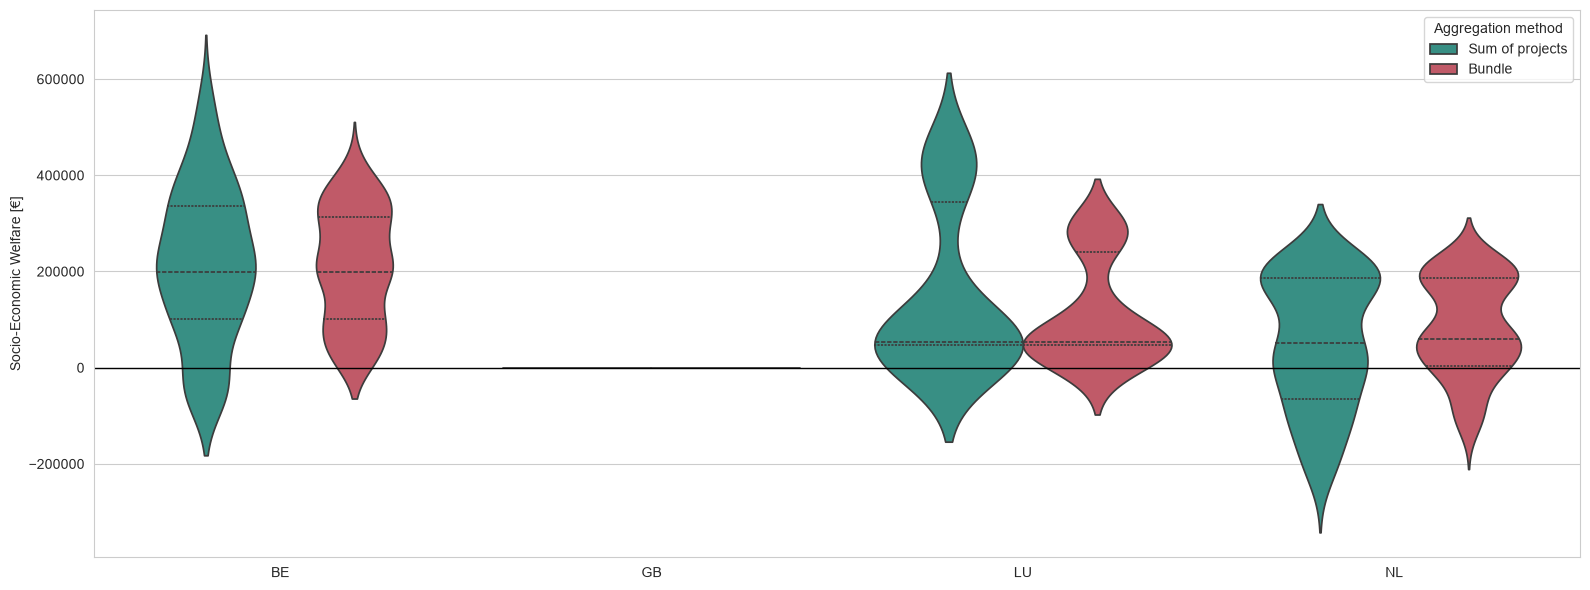

In [234]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(16, 6))

# Draw violins
sns.violinplot(
    data=df,
    x="country",
    y="effect",
    hue="counterfactual",
#    order=["BE", "NL"],
    hue_order=["Sum of projects", "Bundle"],
    palette={
        "Sum of projects": "#2a9d8f",
        "Bundle": "#d1495b",
    },
    inner="quartile",
    dodge=True,
    ax=ax,
)



# Get y-limits after plotting
ymin, ymax = ax.get_ylim()

# Add colored backgrounds
# For each country, seaborn places the violins at roughly:
# center ± 0.2
# for i, country in enumerate(["BE", "NL"]):
#
#     # cf_0_sum background (left violin)
#     ax.add_patch(
#         Rectangle(
#             (i - 0.4, ymin),
#             0.4,
#             ymax - ymin,
#             color="tab:blue",
#             alpha=0.08,
#             zorder=0,
#         )
#     )
#
#     # cf_0_pool background (right violin)
#     ax.add_patch(
#         Rectangle(
#             (i, ymin),
#             0.4,
#             ymax - ymin,
#             color="tab:orange",
#             alpha=0.08,
#             zorder=0,
#         )
#     )

ax.axhline(0, color="black", lw=1)
ax.set_ylabel("Socio-Economic Welfare [€]")
ax.set_xlabel("")
ax.legend(title="Aggregation method")

plt.tight_layout()
plt.show()



## in this plot the two effects of the bundle (lower the compensation needed in the expected value and lower the variability) are mixed. an idea is to make it relative to the expected value

In [233]:
df = df[df["counterfactual"].isin(["Sum of projects", "Bundle"])]
df["mean"] = df.groupby(["country","counterfactual"])["effect"].transform("mean")

In [232]:
df["country"] = df["country"].replace({
    "OBZ_BE": "BE",
    "OBZ_NL": "NL",
})

df_grouped = (
    df.groupby(["country", "counterfactual"])
      .sum(numeric_only=True)
      .reset_index()
)

In [240]:
## metric that shows the reduction in standard deviation
(df.groupby(["country", "counterfactual"])["effect"].agg(["mean", "std"])/1000).T

country                 BE                     GB                          LU  \
counterfactual      Bundle Sum of projects Bundle Sum of projects      Bundle   
mean            209.804331      215.141588    0.0             0.0  111.916751   
std             118.173844      159.241044    0.0             0.0  106.508351   

country                                NL                  
counterfactual Sum of projects     Bundle Sum of projects  
mean                150.931808  84.969987       51.664009  
std                 168.248677  99.992625      135.403001

In [213]:
per_country_expected_welfare = df_grouped.groupby(["country","counterfactual"])["effect"].mean()
total_expected_welfare = df_grouped.groupby(["country","counterfactual"])["effect"].mean().groupby(level = "counterfactual").transform("sum")
share_of_expected_benefits = per_country_expected_welfare / total_expected_welfare
share_of_expected_benefits

country  counterfactual 
BE       Bundle             0.598189
         Sum of projects    0.628570
GB       Bundle             0.000000
         Sum of projects    0.000000
LU       Bundle             0.159547
         Sum of projects    0.220486
NL       Bundle             0.242264
         Sum of projects    0.150945
Name: effect, dtype: float64

0    2.098043e+07
1    2.151416e+07
2    0.000000e+00
3    0.000000e+00
4    5.595838e+06
5    7.546590e+06
6    8.496999e+06
7    5.166401e+06
Name: effect, dtype: float64

In [192]:
cost_shares = pd.DataFrame({
    "country": ["BE", "NL", "LU", "GB"],
    "cost_share": [0.25, 0.25, 0.0, 0.5]
})

In [193]:
def compute_compensation(benefits, cost_shares, total_cost):
    """
    benefits: MultiIndex Series with levels ['country', 'counterfactual']
    cost_shares: DataFrame with columns ['country', 'cost_share']

    Returns:
        DataFrame with benefit, benefit_share,
        target_benefit and compensation.
    """

    df = benefits.rename("benefit").reset_index()

    df = df.merge(cost_shares, on="country", how="left")

    df["total_benefit"] = (
        df.groupby("counterfactual")["benefit"]
          .transform("sum")
    )

    df["benefit_share"] = (
        df["benefit"] / df["total_benefit"]
    )

    df["target_cost"] = (
        df["cost_share"] * total_cost
    )

    df["cost_weighted_on_benefit"] = (
        df["benefit_share"] * total_cost
    )

    df["compensation"] = (
        df["target_cost"] - df["cost_weighted_on_benefit"]
    )

    df["absolute compensation"] = (
        df["target_cost"] - df["cost_weighted_on_benefit"]
    ).abs()

    return df

In [228]:
compute_compensation(per_country_expected_welfare, cost_shares, 100000).groupby("counterfactual")["absolute compensation"].sum()/2

counterfactual
Bundle             50773.576670
Sum of projects    59905.547603
Name: absolute compensation, dtype: float64

In [242]:
df_compensation = compute_compensation(per_country_expected_welfare, cost_shares, 100000)

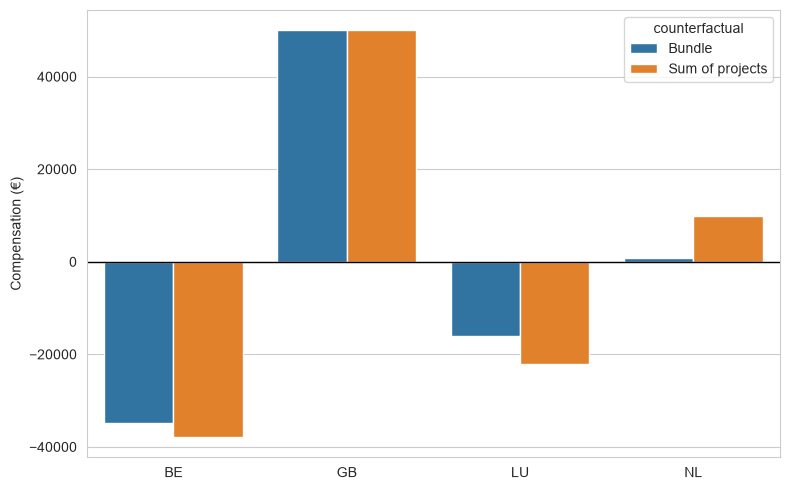

In [248]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_compensation,
    x="country",
    y="compensation",
    hue="counterfactual",
)

plt.axhline(0, color="black", lw=1)
plt.ylabel("Compensation (€)")
plt.xlabel("")
plt.tight_layout()
plt.show()
